# Time-series Forecasting with Naive Approaches and Baselining
_**Consider appropriate time-series dataset, apply naive approaches to forecast and then baseline a model with respect it its forecasting performance.**_

In this experiment, the following naive approaches will be experimented to forecast the quarterly earnings per share (EPS) of Johnson & Johnson.

1) Historical mean of the entire train set
2) Historical mean of the last year in the train set
3) Last known value of the train set
4) Naive seasonality

In [1]:
# Imports packages

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

### Retrieving & Analyzing the Data

The dataset that was considered in this experiment represents the quarterly EPS in US dollars of Johnson & Johnson stock from 1960 to 1980.

In [2]:
# Loads the dataset
eps = pd.read_csv("./../../data/johnson_&_johnson_stock_EPS.csv")

display(eps.head())     # Shows few instances from top

display(eps.tail())     # Shows few instances from bottom

,date,data
0,1960-01-01,0.71
1,1960-04-01,0.63
2,1960-07-02,0.85
3,1960-10-01,0.44
4,1961-01-01,0.61


,date,data
79,1979-10-01,9.99
80,1980-01-01,16.20
81,1980-04-01,14.67
82,1980-07-02,16.02
83,1980-10-01,11.61


In [3]:
# Checks the shape of the dataset
print(eps.shape)

(84, 2)


In [4]:
# Checks the descriptive statistics 
# (e.g. minimum, maximum, mean, standard deviation, four quartiles) of EPS for all quartes
print(eps.describe())

            data
count  84.000000
mean    4.799762
std     4.309991
min     0.440000
25%     1.247500
50%     3.510000
75%     7.132500
max    16.200000


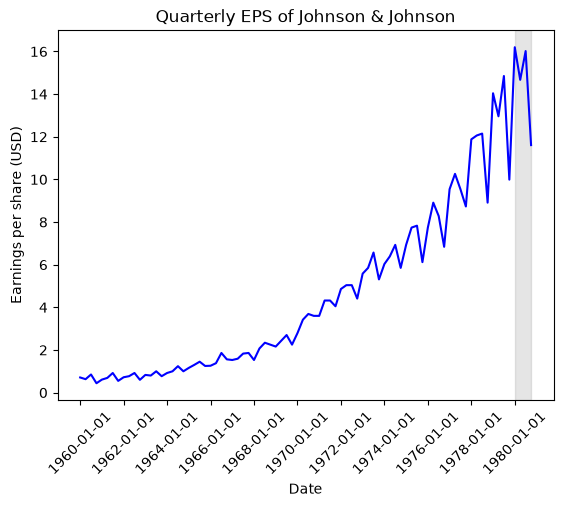

In [5]:
# Visualizes the time series


fig, ax = plt.subplots()
ax.plot(eps['date'], eps['data'], "b-")
ax.xaxis.set_major_locator(MultipleLocator(8))
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Earnings per share (USD)')
plt.axvspan(80, 83, color='#808080', alpha=0.2)   # Highlights forecasting region
plt.title("Quarterly EPS of Johnson & Johnson")   # Sets plot title
plt.show()

**Below ones are the findings out of the above figure.**
1. It has a trend since EPS is increasing over time.
2. There is a seasonality, since there are peaks and troughs (a low point between two high points) repeated over the course of a year, or four quarters.

### Preparing Datasets

In [6]:
# Splits data into train and test set.

X_train = eps[:-4]    # Contain EPS data for all quarters except the last four.
X_test = eps[-4:]     # Contains the EPS data only the last four quarters.

### Forecasting using Historical  Mean of the Entire Train Set
It simply assumes that future values will be equal to the mean of the values over a certain past period.



In [7]:
# Calculates the historical mean of the entire train set
hist_mean = np.mean(X_train['data'])

print(f"The average EPS between 1960 and 1979 was ${hist_mean: .2f}.")

The average EPS between 1960 and 1979 was $ 4.31.


In [8]:
# Creates a new column that holds the historical mean of the train set 
# as naive forecast for next four quarters of 1980.

X_test.loc[:, "forecast_mean"] = hist_mean

print("The EPS forcast (using historical mean) for the four quarters of 1980 are as follows.")
display(X_test)

The EPS forcast (using historical mean) for the four quarters of 1980 are as follows.


,date,data,forecast_mean
80,1980-01-01,16.20,4.3085
81,1980-04-01,14.67,4.3085
82,1980-07-02,16.02,4.3085
83,1980-10-01,11.61,4.3085


In [9]:
# Evaluates forecasting performance
hist_mean_mape = mean_absolute_percentage_error(X_test["data"], X_test["forecast_mean"])

print(f"MAPE for historical mean based forcast is {hist_mean_mape: .2f}")

MAPE for historical mean based forcast is  0.70


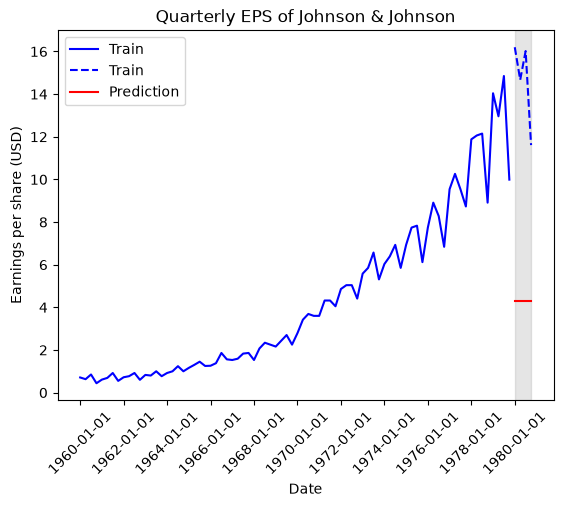

In [10]:
# Plots the forecasting

fig, ax = plt.subplots()
ax.plot(X_train['date'], X_train['data'], 'b-', label='Train')
ax.plot(X_test['date'], X_test['data'], 'b--', label='Train')
plt.plot(X_test['date'], X_test['forecast_mean'], 'r-', label='Prediction')
ax.xaxis.set_major_locator(MultipleLocator(8))
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Earnings per share (USD)')
plt.axvspan(80, 83, color='#808080', alpha=0.2)   # Highlights forecasting region
plt.title("Quarterly EPS of Johnson & Johnson")   # Sets plot title
plt.legend()
plt.show()

### Forecasting using Last Year's Mean

It was found that forecasting using entire historical mean did not do well because earlier values do not seem to be predictive of future values in the long term because of the positive trend component in the dataset. Earlier values are too small to be representative of the new level the EPS reaches toward the end of 1979 and onwards. The followings experiment by taking the mean of the last year in the training set to forecast each quarter in the following year.

In [11]:
# Calculates the mean of the four quarters in last year [1979] in train set 
last_year_mean = np.mean(X_train.data[-4:])

print(f"The mean EPS of last four quarters (in 1979) was ${last_year_mean: .2f}.")

The mean EPS of last four quarters (in 1979) was $ 12.96.


In [12]:
# Creates a new column that holds the mean of the last 4 quarters 
# in 1979 to naively forecast this value for each quarter of 1980.

X_test.loc[:, 'forecast_last_year_mean'] = last_year_mean

print("The EPS forcast (using last year's mean) for the four quarters of 1980 are as follows.")
display(X_test)

The EPS forcast (using last year's mean) for the four quarters of 1980 are as follows.


,date,data,forecast_mean,forecast_last_year_mean
80,1980-01-01,16.20,4.3085,12.96
81,1980-04-01,14.67,4.3085,12.96
82,1980-07-02,16.02,4.3085,12.96
83,1980-10-01,11.61,4.3085,12.96


In [13]:
# Evaluates forecasting performance
last_year_mean_mape = mean_absolute_percentage_error(X_test["data"], X_test["forecast_last_year_mean"])

print(f"MAPE for last year mean based forcast is {last_year_mean_mape: .2f}")

MAPE for last year mean based forcast is  0.16


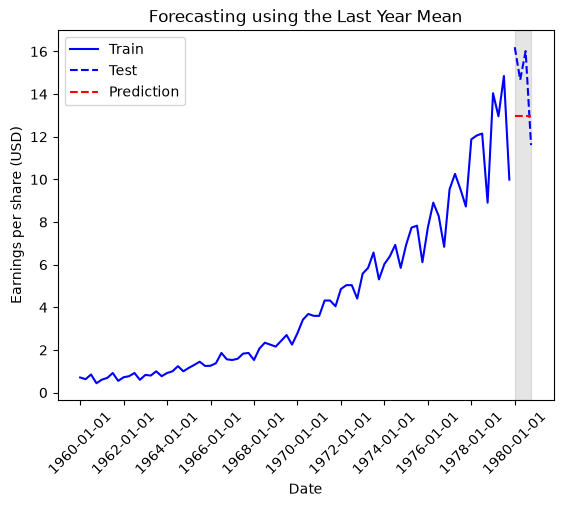

In [14]:
# Plots the forecasting

fig, ax = plt.subplots()
ax.plot(X_train['date'], X_train['data'], 'b-', label='Train')
ax.plot(X_test['date'], X_test['data'], 'b--', label='Test')
ax.plot(X_test['date'], X_test['forecast_last_year_mean'], 'r--', label='Prediction')
ax.xaxis.set_major_locator(MultipleLocator(8))
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Earnings per share (USD)')
plt.axvspan(80, 83, color='#808080', alpha=0.2)
plt.legend()
plt.title("Forecasting using the Last Year Mean")
plt.show()

This new simple baseline is a clear improvement over the previous one as MAPE was decreased from 70% to 16%.

### Forecasting using Last Known Value

As best baseline has been the mean of the last recorded year in our training set, the next hypothesis that could be tested is that using the last known value of the training set as a baseline model if it provides better forecasts.

In [15]:
# Gets the last known value of the train set, which corresponds to the EPS for the last quarter of 1979.
last_value = X_train.data.iloc[-1]

print(f"The last known EPS (in 1979) was ${last_value: .2f}.")

The last known EPS (in 1979) was $ 9.99.


In [16]:
# Creates a new column that holds this last value 
# to naively forecast for each quarter of 1980.

X_test.loc[:, 'forecast_last_value'] = last_value

print("The EPS forcast (using last know value) for the four quarters of 1980 are as follows.")
display(X_test)

The EPS forcast (using last know value) for the four quarters of 1980 are as follows.


,date,data,forecast_mean,forecast_last_year_mean,forecast_last_value
80,1980-01-01,16.20,4.3085,12.96,9.99
81,1980-04-01,14.67,4.3085,12.96,9.99
82,1980-07-02,16.02,4.3085,12.96,9.99
83,1980-10-01,11.61,4.3085,12.96,9.99


In [17]:
# Evaluates forecasting performance
last_value_mape = mean_absolute_percentage_error(X_test["data"], X_test["forecast_last_value"])

print(f"MAPE for last known value based forcast is {last_value_mape: .2f}")

MAPE for last known value based forcast is  0.30


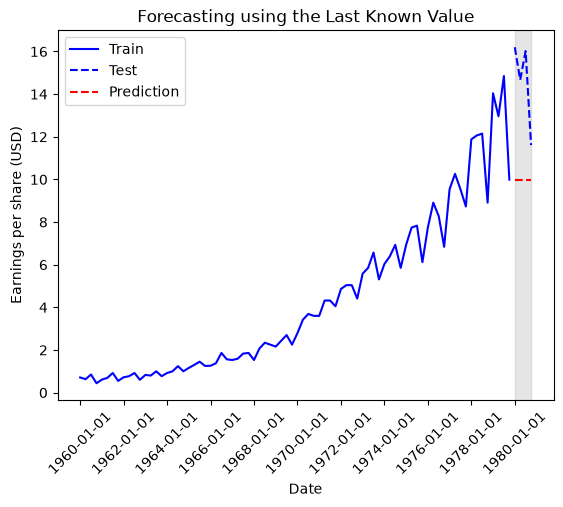

In [18]:
# Plots the forecasting

fig, ax = plt.subplots()
ax.plot(X_train['date'], X_train['data'], 'b-', label='Train')
ax.plot(X_test['date'], X_test['data'], 'b--', label='Test')
ax.plot(X_test['date'], X_test['forecast_last_value'], 'r--', label='Prediction')
ax.xaxis.set_major_locator(MultipleLocator(8))
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Earnings per share (USD)')
plt.axvspan(80, 83, color='#808080', alpha=0.2)
plt.legend()
plt.title("Forecasting using the Last Known Value")
plt.show()


The new hypothesis with a MAPE of 30% did not improve upon the last performance baseline (16%) that was built since.

### Forecasting using Naive Seasonality

As there is clear cyclical patterns in the data, this component can be considered to build a new baseline model using seasonality. For example, if the EPS is $14.04 for the first quarter of 1979, then the EPS for the first quarter of 1980 will also be $14.04.

In [19]:
# Copies last four values of the train set, which correspond to the four quarters of 1979,
# and assigning them to the corresponding quarters in 1980. 

X_test.loc[:, 'forecast_last_quarter'] = X_train['data'][-4:].values

print("The EPS forcast (using naive seasonality) for the four quarters of 1980 are as follows.")
display(X_test)

The EPS forcast (using naive seasonality) for the four quarters of 1980 are as follows.


,date,data,forecast_mean,forecast_last_year_mean,forecast_last_value,forecast_last_quarter
80,1980-01-01,16.20,4.3085,12.96,9.99,14.04
81,1980-04-01,14.67,4.3085,12.96,9.99,12.96
82,1980-07-02,16.02,4.3085,12.96,9.99,14.85
83,1980-10-01,11.61,4.3085,12.96,9.99,9.99


In [20]:
# Evaluates forecasting performance
last_quarter_mape = mean_absolute_percentage_error(X_test["data"], X_test["forecast_last_quarter"])

print(f"MAPE naive seasonality based forcast is {last_quarter_mape: .2f}")

MAPE naive seasonality based forcast is  0.12


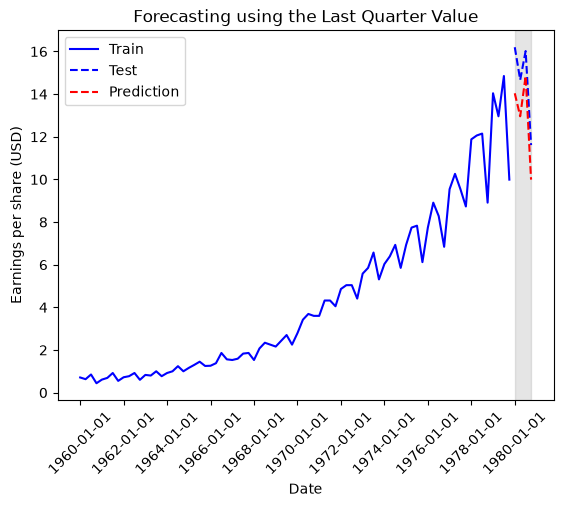

In [21]:
# Plots the forecasting

fig, ax = plt.subplots()
ax.plot(X_train['date'], X_train['data'], 'b-', label='Train')
ax.plot(X_test['date'], X_test['data'], 'b--', label='Test')
ax.plot(X_test['date'], X_test['forecast_last_quarter'], 'r--', label='Prediction')
ax.xaxis.set_major_locator(MultipleLocator(8))
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Earnings per share (USD)')
plt.axvspan(80, 83, color='#808080', alpha=0.2)
plt.legend()
plt.title("Forecasting using the Last Quarter Value")
plt.show()


This gives us a MAPE of 12%, which is the lowest MAPE for all the baselines tested so far.

### Observations

- The EPS has a trend since it is increasing over time.

- There is a seasonality, since there are peaks and troughs (a low point between two high points) repeated over the course of a year, or four quarters.

- In general, future values depend on past values, but not those too far back in time. It was evident from the fact that predicting the mean EPS from 1960 to 1979 yielded worse forecasts than predicting the mean EPS over 1979. 

- Naive seasonal forecast resulted in the lowest MAPE of all the baselines built in this experiment meaning seasonality has a significant impact on future values since repeating the last season into the future yields fairly accurate forecasts. For a more complex forecasting model, seasonal effects might need to be considered.

- A baseline model serves as a basis to compare the MAPE of a relatively complex model. A model with lowerest MAPE would be considered as a best model.